# Bias e risoluzione della posizione ricostruita

Origine: `~/juno/bias/graphs.ipynb`.

Copia organizzata per la consultazione: le celle eseguibili e gli output originali sono conservati. I titoli aggiunti sono celle Markdown; i risultati salvati non sono stati ricalcolati. Eseguire dalla cartella di questo notebook. I dati ROOT esterni e gli eventuali problemi già presenti sono descritti in `docs/DATI_E_PERCORSI.md` nella radice del repository.


## Librerie


In [2]:
import matplotlib.pyplot as plt 
import uproot
import numpy as np

## Bias e risoluzione lungo l’asse z


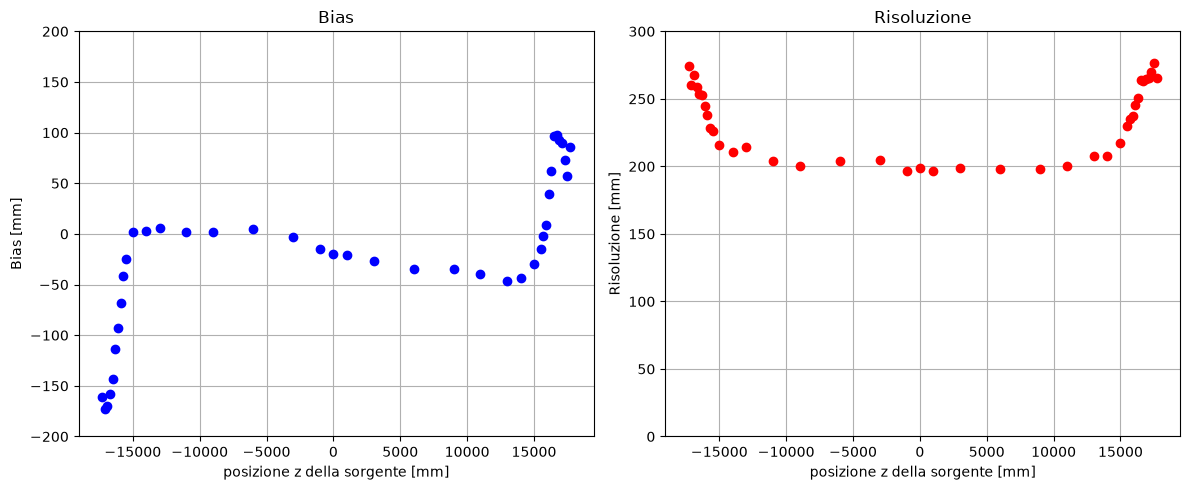

In [3]:
file = uproot.open("output6.root")
bias = file["bias"]    
res = file["resolution"]

x = bias.member("fX")
b = bias.member("fY")
b_err = bias.member("fEY")


r= res.member("fY")
r_err = res.member("fEY")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].errorbar(x, b, fmt='o', label='Bias', color='blue')
ax[0].set_xlabel('posizione z della sorgente [mm]')
ax[0].set_ylabel('Bias [mm]')
ax[0].set_title('Bias')
ax[0].grid()
ax[0].set_ylim(-200, 200)

ax[1].errorbar(x, r, fmt='o', label='Risoluzione', color='red')
ax[1].set_xlabel('posizione z della sorgente [mm]')
ax[1].set_ylabel('Risoluzione [mm]')
ax[1].set_title('Risoluzione')
ax[1].grid()
ax[1].set_ylim(0, 300)
plt.tight_layout()
plt.show()



## Distribuzione della posizione e fit gaussiano


Chi2 ridotto: 0.9896


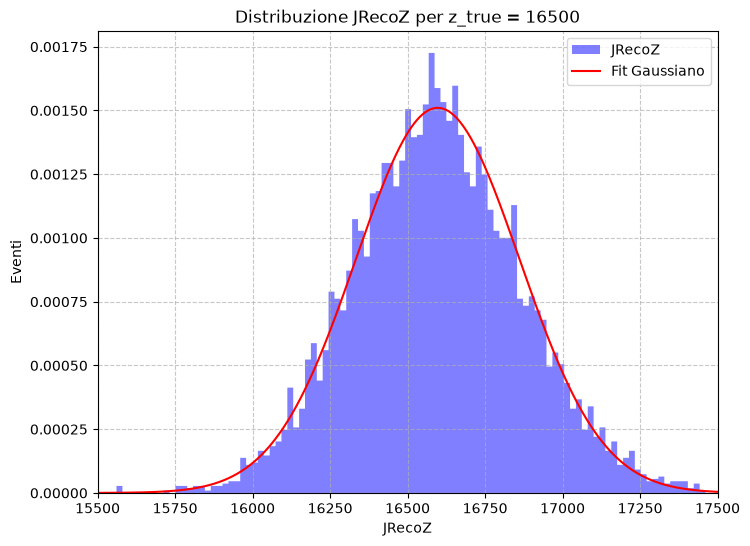

In [4]:
file = uproot.open("output4.root")

bias = file["bias"]    
res = file["resolution"]

b = bias.member("fY")
r= res.member("fY")

mu= b[18]+16500
sigma= r[18]


if "z_16500;1" in file.keys():
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    
    # Estraiamo l'istogramma
    hist = file["z_16500"]
    
    # uproot ha un comodo metodo to_numpy() che restituisce gli accessi (counts) e i bordi dei bin (edges)
    counts, edges = hist.to_numpy()
    bin_width = edges[1] - edges[0]
    total_events = np.sum(counts)
    counts_norm = counts / (total_events * bin_width)

    x_fit = np.linspace(15500, 17500, 1000)
    y_fit = 1/(sigma*np.sqrt(2*np.pi)) * np.exp(-0.5 * ((x_fit - mu)/sigma)**2)
    
    # Disegniamo l'istogramma
    ax1.stairs(counts_norm, edges, fill=True, alpha=0.5, color='blue', label='JRecoZ')
    ax1.set_xlim(15500, 17500)
    ax1.set_title("Distribuzione JRecoZ per z_true = 16500")
    ax1.set_xlabel("JRecoZ")
    ax1.set_ylabel("Eventi")
    ax1.grid(True, linestyle='--', alpha=0.7)

    ax1.plot(x_fit, y_fit, color='red', label='Fit Gaussiano')
    
    ax1.legend()

    print(f"Chi2 ridotto: {0.9896}")

## Caricamento delle run di confronto


In [21]:
import uproot

file = uproot.open("RUN14399_26B.root")
tree = file["CdEvents"]

data= tree.arrays(library="np")

In [22]:
file = uproot.open("RUN14417_26B.root")
tree2 = file["CdEvents"]

data2 = tree2.arrays(library="np")

In [23]:
file = uproot.open("RUN14453_26B.root")
tree3 = file["CdEvents"]

data3 = tree3.arrays(library="np")

## Spettro energetico e selezione degli eventi


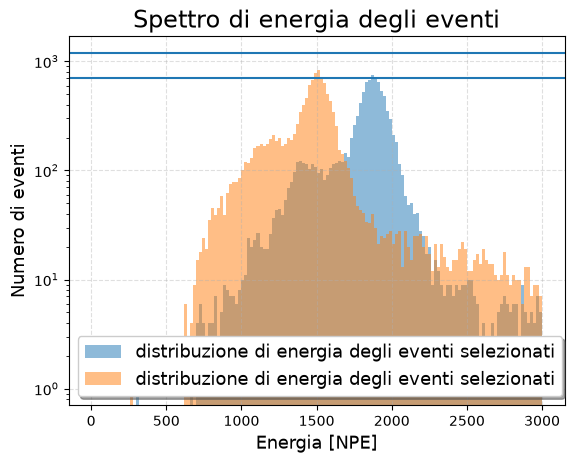

In [24]:
import matplotlib.pyplot as plt 
import numpy as np 
x3 = data3["JRecoX"]
y3 = data3["JRecoY"]
z3 = data3["JRecoZ"]

energy3= data3["NPE"]

z = data["JRecoZ"]
x = data["JRecoX"]
y= data["JRecoY"]

energy= data["NPE"]

mask= (z>14000) & (z<16000) & (np.abs(x)<1000) & (np.abs(y)<1000)

mask3= (z3>-18300) & (z3<-16300) & (np.abs(x3)<1000) & (np.abs(y3)<1000)

# plt.hist(energy, bins=150, range=(0, 3000), label = "distribuzione di eneergia di tutti gli eventi")

plt.hist(energy[mask], bins= 150, range = (0,3000), label = "distribuzione di energia degli eventi selezionati", alpha=0.5)
plt.hist(energy3[mask3], bins= 150, range = (0,3000), label = "distribuzione di energia degli eventi selezionati", alpha= 0.5)
plt.xlabel("Energia [NPE]")
plt.yscale("log")
plt.title("Spettro di energia degli eventi")
plt.ylabel("Numero di eventi")
plt.grid(linestyle="--", alpha= 0.4)

plt.axhline(1200)
plt.axhline(700)

plt.legend(loc= "lower left", shadow = True )

## Coordinate ricostruite: run 14399


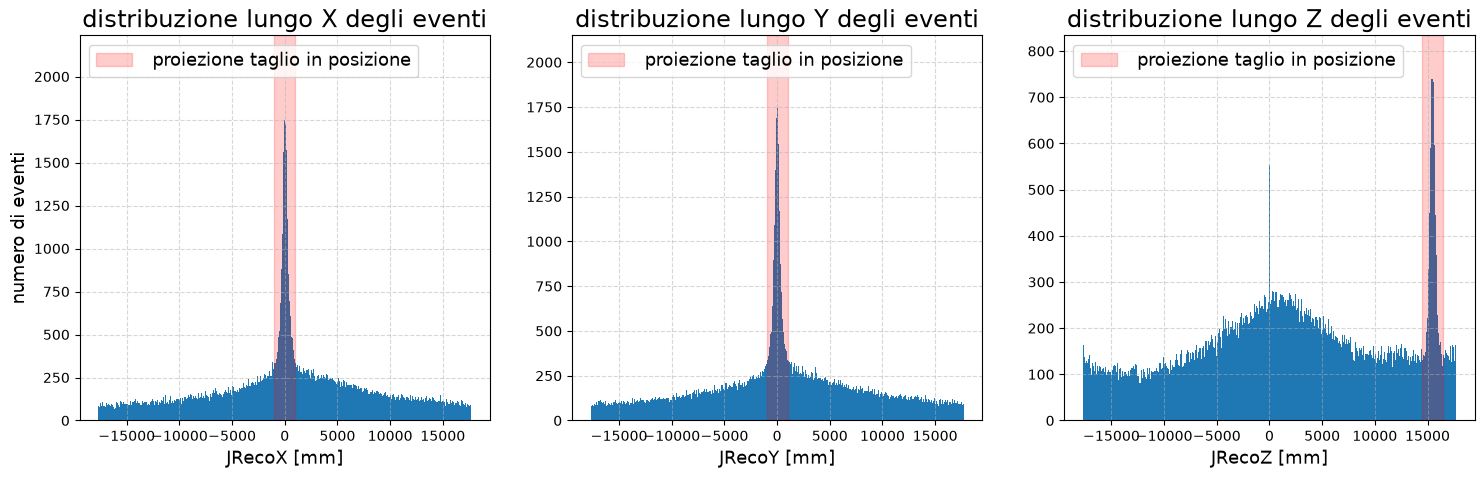

In [25]:
import matplotlib.pyplot as plt 
import numpy as np 
z = data["JRecoZ"]
x = data["JRecoX"]
y= data["JRecoY"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

position= [0, 0 , 15500]
nome = ["X", "Y", "Z"]
dati = [x, y, z]

for i, pos in enumerate(position):

    ax[i].hist(x=dati[i], bins=1000, range=(-17700, 17700))
    ax[i].set_xlabel("JReco"+ nome[i] + " [mm]")
    if(i==0):
        ax[i].set_ylabel("numero di eventi")
    ax[i].set_title("distribuzione lungo "+ nome[i] + " degli eventi")
    ax[i].axvspan(pos-1000, pos+ 1000, alpha =0.2, color = "red", label = " proiezione taglio in posizione")
    ax[i].legend(loc= "upper left")
    ax[i].grid(linestyle="--", alpha = 0.5,)

plt.show()

## Coordinate ricostruite: run 14417


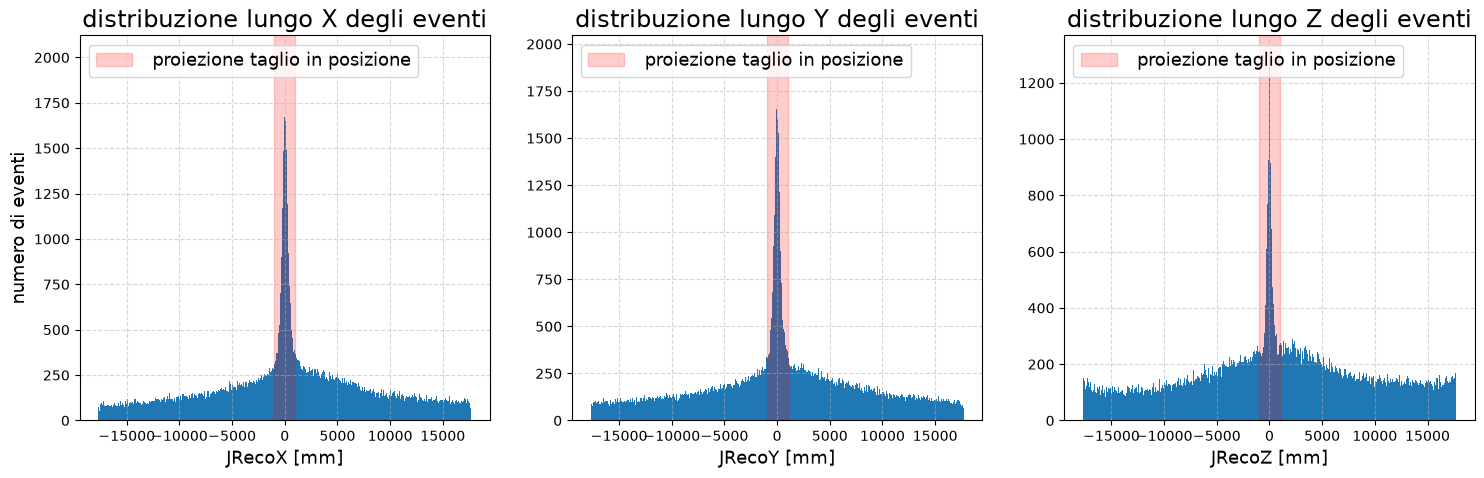

In [26]:
import matplotlib.pyplot as plt 
import numpy as np 
z2 = data2["JRecoZ"]
x2 = data2["JRecoX"]
y2= data2["JRecoY"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

position= [0, 0 , 0]
nome = ["X", "Y", "Z"]
dati = [x2, y2, z2]

for i, pos in enumerate(position):

    ax[i].hist(x=dati[i], bins=1000, range=(-17700, 17700))
    ax[i].set_xlabel("JReco"+ nome[i] + " [mm]")
    if(i==0):
        ax[i].set_ylabel("numero di eventi")
    ax[i].set_title("distribuzione lungo "+ nome[i] + " degli eventi")
    ax[i].axvspan(pos-1000, pos+ 1000, alpha =0.2, color = "red", label = " proiezione taglio in posizione")
    ax[i].legend(loc= "upper left")
    ax[i].grid(linestyle="--", alpha = 0.5,)

plt.show()


## Spettro energetico nella regione centrale


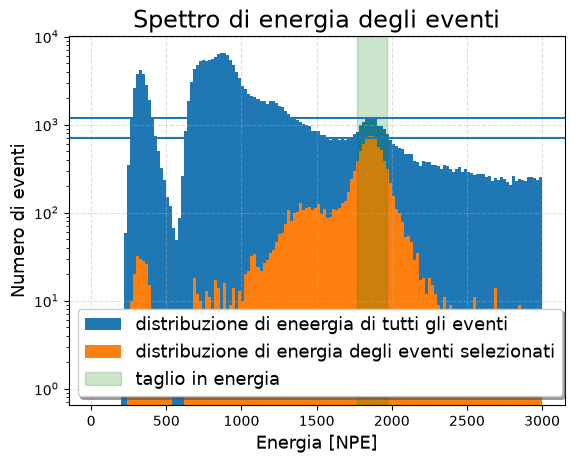

In [27]:
energy= data2["NPE"]

mask= (np.abs(z2)<1000) & (np.abs(x2)<1000) & (np.abs(y2)<1000)

plt.hist(energy, bins=150, range=(0, 3000), label = "distribuzione di eneergia di tutti gli eventi")
plt.hist(energy[mask], bins= 150, range = (0,3000), label = "distribuzione di energia degli eventi selezionati")
plt.xlabel("Energia [NPE]")
plt.yscale("log")
plt.title("Spettro di energia degli eventi")
plt.ylabel("Numero di eventi")
plt.axvspan(1770, 1970, color= "green", alpha = 0.2, label = "taglio in energia")
plt.grid(linestyle="--", alpha= 0.4)

plt.axhline(1200)
plt.axhline(700)

plt.legend(loc= "lower left", shadow = True )

## Spettro energetico nella regione periferica


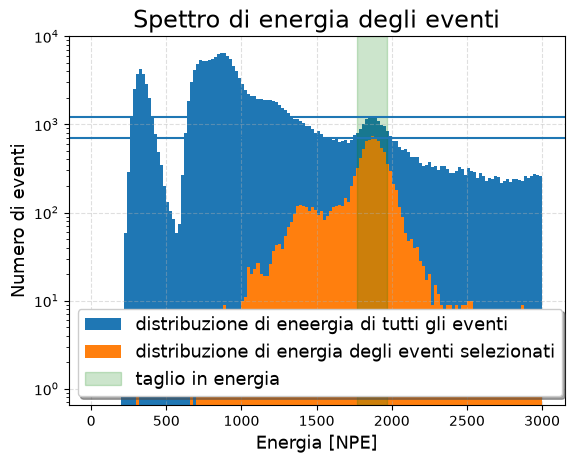

In [28]:
energy= data["NPE"]

mask= (z>14000) & (z<16000) & (np.abs(x)<1000) & (np.abs(y)<1000)

plt.hist(energy, bins=150, range=(0, 3000), label = "distribuzione di eneergia di tutti gli eventi")
plt.hist(energy[mask], bins= 150, range = (0,3000), label = "distribuzione di energia degli eventi selezionati")
plt.xlabel("Energia [NPE]")
plt.yscale("log")
plt.title("Spettro di energia degli eventi")
plt.ylabel("Numero di eventi")
plt.axvspan(1770, 1970, color= "green", alpha = 0.2, label = "taglio in energia")
plt.grid(linestyle="--", alpha= 0.4)

plt.axhline(1200)
plt.axhline(700)

plt.legend(loc= "lower left", shadow = True )

## Fit della posizione z dopo i tagli


226.61353


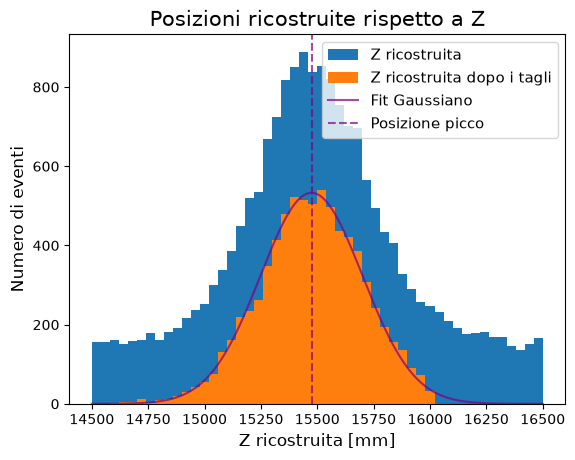

In [ ]:
mask= (energy<2000) & (energy> 1600) & mask 
a= np.sum(mask)

plt.rcParams.update({
    'font.size': 14,          # Dimensione di base per tutto
    'axes.titlesize': 15,     # Titoli dei grafici ('Bias', 'Risoluzione')
    'axes.labelsize': 12,     # Etichette degli assi (es. 'posizione z...')
    'xtick.labelsize': 10,    # Numeri sull'asse X
    'ytick.labelsize': 10,    # Numeri sull'asse Y
    'legend.fontsize': 10     # Testo dentro la legenda
})

plt.hist(z, bins= 50, range = (14500, 16500), label= "Z ricostruita")
plt.hist(z[mask], bins = 50, range = (14500, 16500), label = "Z ricostruita dopo i tagli")

from scipy.stats import norm
x = np.linspace(14500, 16500, 1000)
mu, sigma = norm.fit(z[mask])
plt.plot(x, norm.pdf(x, mu , sigma)* a* 2000./50., color= "purple", label = "Fit Gaussiano", alpha= 0.7)
plt.axvline(mu, linestyle= "--", alpha= 0.7, color= "purple", label= "Posizione picco")
plt.ylabel("Numero di eventi")
plt.xlabel("Z ricostruita [mm]")

plt.legend( shadow=False)
plt.title("Posizioni ricostruite rispetto a Z")

print(sigma)



## Confronto del bias e della risoluzione con e senza correzione


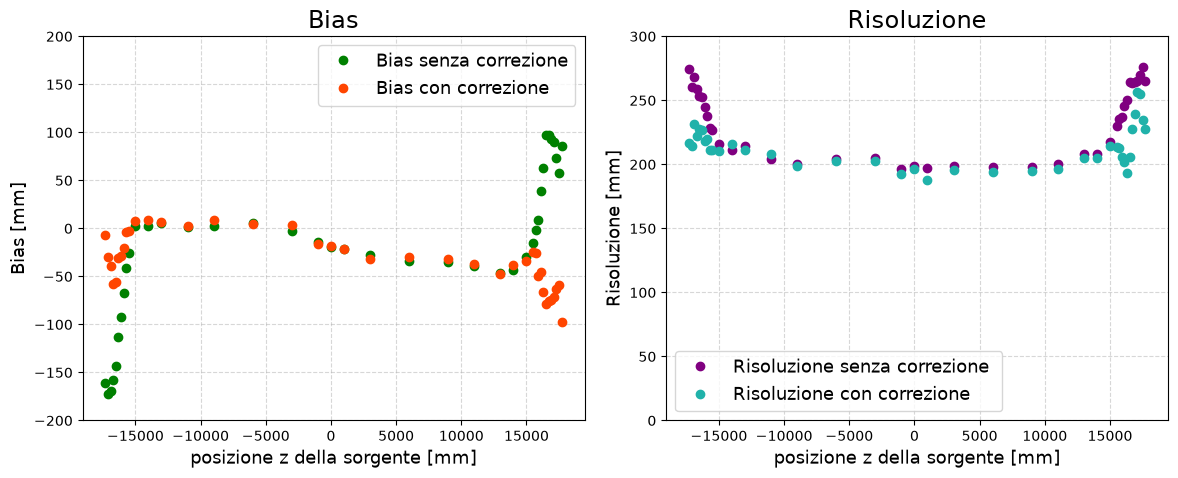

In [18]:
import uproot 
import matplotlib.pyplot as pltù

plt.rcParams.update({
    'font.size': 14,          # Dimensione di base per tutto
    'axes.titlesize': 17,     # Titoli dei grafici ('Bias', 'Risoluzione')
    'axes.labelsize': 13,     # Etichette degli assi (es. 'posizione z...')
    'xtick.labelsize': 10,    # Numeri sull'asse X
    'ytick.labelsize': 10,    # Numeri sull'asse Y
    'legend.fontsize': 13     # Testo dentro la legenda
})

file = uproot.open("output5.root")
bias = file["bias"]    
res = file["resolution"]

file2= uproot.open("output6.root")
bias2 = file2["bias"]    
res2 = file2["resolution"]


x = bias.member("fX")
b = bias.member("fY")
b_err = bias.member("fEY")

x2 = bias2.member("fX")
b2 = bias2.member("fY")
b_err2 = bias2.member("fEY")

r= res.member("fY")
r_err = res.member("fEY")

r2= res2.member("fY")
r_err2 = res2.member("fEY")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].errorbar(x2, b2, fmt='o', label='Bias senza correzione', color='green')
ax[0].set_xlabel('posizione z della sorgente [mm]')
ax[0].set_ylabel('Bias [mm]')
ax[0].set_title('Bias')
ax[0].grid()
ax[0].grid(linestyle= "--", alpha= 0.5)

ax[0].errorbar(x, b ,fmt='o', label='Bias con correzione', color='orangered')
ax[0].set_xlabel('posizione z della sorgente [mm]')
ax[0].set_ylabel('Bias [mm]')
ax[0].set_title('Bias')
ax[0].legend()
ax[0].set_ylim(-200, 200)

ax[1].errorbar(x2, r2, fmt='o', label='Risoluzione senza correzione ', color='purple')
ax[1].set_xlabel('posizione z della sorgente [mm]')
ax[1].set_ylabel('Risoluzione [mm]')
ax[1].set_title('Risoluzione')
ax[1].grid(linestyle= "--", alpha= 0.5)

ax[1].errorbar(x, r, fmt='o', label='Risoluzione con correzione', color='lightseagreen')
ax[1].set_xlabel('posizione z della sorgente [mm]')
ax[1].set_ylabel('Risoluzione [mm]')
ax[1].set_title('Risoluzione')
ax[1].legend()
ax[1].set_ylim(0, 300)

plt.tight_layout()
plt.show()

## Riepilogo numerico delle prestazioni


In [15]:
import numpy as np
mask = np.abs(x)>15000

print(np.mean(np.abs(b[mask])))
print(np.mean(np.abs(b2[mask])))

mask = x >15000

print(np.mean(np.abs(b[mask])))
print(np.mean(np.abs(b2[mask])))

mask = x <15000

print(np.mean(np.abs(b[mask])))
print(np.mean(np.abs(b2[mask])))

print(np.mean(r))
print(np.mean(r2))

mask = np.abs(x)>15000
print(np.mean(r[mask]))
print(np.mean(r2[mask]))

45.63953859142732
84.79611183318602
60.82042563327044
60.07151461844993
22.654418072006965
55.72269907945535
213.026204184215
231.94311764421457
221.58949855326838
253.25264674631188


In [16]:
print("z = ", x2)
print("risoluzione senza correzione = ", r2)
print("risoluzione con correzione = ", r)

z =  [-17300. -17100. -16900. -16700. -16500. -16300. -16100. -15900. -15700.
 -15500. -15000. -14000. -13000. -11000.  -9000.  -6000.  -3000.  -1000.
      0.   1000.   3000.   6000.   9000.  11000.  13000.  14000.  15000.
  15500.  15700.  15900.  16100.  16300.  16500.  16700.  16900.  17100.
  17300.  17500.  17700.]
risoluzione senza correzione =  [274.49525338 260.36884627 267.91067985 258.93196443 253.55067879
 252.84302309 244.48307249 237.70267982 228.52457029 226.50527242
 215.6309039  210.88136218 214.55357241 203.87637689 200.05234486
 204.35676567 204.77934053 196.77069314 198.45176705 196.90287827
 198.598359   197.83483719 197.82616832 200.50073312 207.84317889
 207.94634849 217.4177298  229.66483706 235.23140938 237.00523078
 245.23742854 250.29970567 264.13562614 263.2593096  264.40568096
 265.44210143 269.72793901 276.37501108 265.45790795]
risoluzione con correzione =  [216.6411598  214.21387364 231.76724199 222.54126233 227.4916045
 226.72594784 218.4558427  219.755